<a href="https://colab.research.google.com/github/amulyasundaresan/Midterm-1/blob/main/Notebooks/midterm_combined_notebook_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 Midterm: Walmart Hurricane Analytics

## 1. Setup

In [1]:
import os, re, time, glob, sqlite3, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
print('pandas', pd.__version__)

pandas 2.2.3


In [2]:
# ---- Decision log: every cleaning decision goes through log() -------------------------------
DECISIONS = []

def log(file_name, step, decision, rows_affected):
    DECISIONS.append({'file': file_name, 'step': step, 'decision': decision,
                      'rows_affected': int(rows_affected)})
    print(f"[{file_name}] {step}: {decision} ({int(rows_affected):,} row(s))")

def show_log():
    return pd.DataFrame(DECISIONS)

## 2. Data loading



In [3]:
GITHUB_RAW = 'https://raw.githubusercontent.com/amulyasundaresan/Midterm-1/refs/heads/main/Data'

def get_data(filename):
    for folder in ['data', '../data', '/content', '.'] + glob.glob('/kaggle/input/*'):
        path = os.path.join(folder, filename)
        if os.path.exists(path):
            return path
    os.makedirs('data', exist_ok=True)
    dest = os.path.join('data', filename)
    print(f'{filename} not found locally, downloading from GitHub...')
    urllib.request.urlretrieve(f'{GITHUB_RAW}/{filename}', dest)
    return dest

RAW = {
    'transactions': pd.read_csv(get_data('walmart_transactions.csv')),
    'stores':       pd.read_csv(get_data('store_locations.csv')),
    'products':     pd.read_csv(get_data('product_catalog.csv')),
    'dcs':          pd.read_csv(get_data('distribution_centers.csv')),
}

# The SQLite database
conn = sqlite3.connect(get_data('inventory_and_sales.db'))
print('tables in the database:', pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", conn)['name'].tolist())
RAW['inventory'] = pd.read_sql('SELECT * FROM inventory_levels', conn)
RAW['daily_sales'] = pd.read_sql('SELECT * FROM daily_sales_summary', conn)

for name, df in RAW.items():
    print(f'{name:13s} {df.shape[0]:>7,} rows x {df.shape[1]} cols')

walmart_transactions.csv not found locally, downloading from GitHub...
store_locations.csv not found locally, downloading from GitHub...
product_catalog.csv not found locally, downloading from GitHub...
distribution_centers.csv not found locally, downloading from GitHub...
inventory_and_sales.db not found locally, downloading from GitHub...
tables in the database: ['daily_sales_summary', 'inventory_levels']
transactions   25,562 rows x 8 cols
stores             14 rows x 8 cols
products           45 rows x 7 cols
dcs                 5 rows x 8 cols
inventory       4,320 rows x 6 cols
daily_sales     3,600 rows x 5 cols


In [4]:
# Profile of the raw transactions
def profile(df, name='dataset'):
    print(f'=== {name} ===')
    print(f'{len(df):,} rows x {len(df.columns)} columns\n')
    print(pd.DataFrame({
        'dtype': df.dtypes.astype(str),
        'nulls': df.isnull().sum(),
        'null_pct': (100 * df.isnull().mean()).round(1),
        'distinct': df.nunique(),
    }))
    print('\nexact duplicate rows:', df.duplicated().sum())

profile(RAW['transactions'], 'walmart_transactions (RAW)')

=== walmart_transactions (RAW) ===
25,562 rows x 8 columns

                 dtype  nulls  null_pct  distinct
transaction_id  object      0       0.0     25532
store_id        object      0       0.0        60
timestamp       object    886       3.5     23952
sku             object      0       0.0        45
product_name    object      0       0.0        63
category        object      0       0.0        37
quantity         int64      0       0.0        11
unit_price      object      0       0.0      3668

exact duplicate rows: 30


## 3. Lookup tables: categories and the SKU map

**Categories.** Raw spellings seen: `EMERGENCY`, `emergency`, `Emergency`, `Emergency Supplies`, `Groceries`, `Games & Entertainment`, `Health & Wellness`... One map, used for every file.


In [5]:
CATEGORY_MAP = {
    'breakfast': 'Breakfast', 'breakfast foods': 'Breakfast',
    'emergency': 'Emergency Supplies', 'emergency supplies': 'Emergency Supplies',
    'grocery': 'Grocery', 'groceries': 'Grocery',
    'baby': 'Baby Products', 'baby products': 'Baby Products',
    'alcohol': 'Alcohol', 'alcohol drinks': 'Alcohol', 'alcoholic beverages': 'Alcohol',
    'game & entertainment': 'Game & Entertainment', 'games & entertainment': 'Game & Entertainment',
    'game': 'Game & Entertainment', 'entertainment': 'Game & Entertainment',
    'health': 'Health', 'health & wellness': 'Health',
    'household': 'Household', 'household essentials': 'Household',
    'electronics': 'Electronics',
    'snacks': 'Snacks',
}
CANONICAL_CATEGORIES = set(CATEGORY_MAP.values())

def clean_category(s):
    key = s.astype('string').str.strip().str.lower()
    return key.map(CATEGORY_MAP).fillna(key.str.title())

In [6]:
# canonical_sku -> (display name, [every SKU variant seen in the catalog / transactions / database])
SKU_FAMILIES = {
    'POPTART-STRAW': ('Pop-Tarts Strawberry',    ['PT-12', 'SKU#459812', 'POPTART-STRAW', 'PT_STRAWBERRY']),
    'WTR_24PK':      ('Bottled Water 24-Pack',   ['WTR-24', 'WATER24PK', 'WTR_24PK']),
    'BATT_AA_4PK':   ('AA Batteries 4-Pack',     ['BATT-100', 'BAT-AA4', 'BATT_AA_4PK']),
    'FLASH-01':      ('LED Flashlight',          ['FLASH-01', 'LED-FLASH']),
    'BEER-24':       ('Light Beer 24-Pack',      ['BEER-24', 'LTBEER24']),
    'MONOPOLY-01':   ('Monopoly Board Game',     ['BG-MONO', 'MONOPOLY-01', 'GAME-MONO']),
    'CARDS-01':      ('Playing Cards',           ['CARDS-01', 'PLAYCARD-STD']),
    'STREAM-01':     ('Roku Streaming Stick',    ['STREAM-01', 'ROKU-STD']),
    'CNSOUP-01':     ('Canned Soup',             ['SOUP-CAN', 'CNSOUP-01']),
    'BREAD-WH':      ('White Bread',             ['BREAD-WH', 'WHITEBREAD']),
    'PB-16':         ('Peanut Butter 16oz',      ['PB-16', 'PNUTBTR-16']),
    'CNDL-EM':       ('Emergency Candles',       ['CNDL-EM', 'CANDLE-EMRG']),
    'FAID-01':       ('First-Aid Kit',           ['FAID-01', 'FIRSTAID-KIT']),
    'CHRG-PORT':     ('Portable Charger',        ['CHRG-PORT', 'PORTCHARGER']),
    'CHIPS-VP':      ('Chips Variety Pack',      ['CHIPS-VP', 'CHIPVARIETY']),
    'PAPERTOWEL6':   ('Paper Towels 6-Pack',     ['PTOWEL-6', 'PAPERTOWEL6']),
    'TOILETPAPER12': ('Toilet Paper 12-Roll',    ['TP-12', 'TOILETPAPER12']),
    'DIAPERS-3':     ('Baby Diapers Size 3',     ['DIAP-S3', 'DIAPERS-3']),
    'BABYFORMULA':   ('Infant Formula',          ['BFORM-01', 'BABYFORMULA']),
    'TARP-HD':       ('Heavy Duty Tarp',         ['TARP-HD', 'HDTARP-01']),
}
SKU_TO_CANON = {v: canon for canon, (_, variants) in SKU_FAMILIES.items() for v in variants}
CANON_NAME   = {canon: name for canon, (name, _) in SKU_FAMILIES.items()}

# SKUs that appear ONLY in the inventory database and in no catalog. We do not guess what they are.
ORPHAN_SKUS = {'UNKNOWN-99', 'LEGACY-PT', 'OLD-BATT-50', 'MISC-001'}

# Safety net: every SKU in every file must be either mapped or a known orphan.
all_skus = (set(RAW['transactions']['sku'].str.strip()) | set(RAW['products']['sku'].str.strip())
            | set(RAW['inventory']['sku'].str.strip().str.upper()))
unmapped = all_skus - set(SKU_TO_CANON) - ORPHAN_SKUS
assert not unmapped, f'SKUs with no mapping, add them to SKU_FAMILIES: {unmapped}'
print(f'{len(SKU_TO_CANON)} SKU variants map to {len(SKU_FAMILIES)} canonical products; {len(ORPHAN_SKUS)} orphan SKUs flagged')

45 SKU variants map to 20 canonical products; 4 orphan SKUs flagged


In [7]:
# Small cleaning helpers shared by every file
def strip_text(df):
    # Strip leading/trailing spaces in every text column. Works on pandas 2 (object) and pandas 3 (str).
    # Returns the cleaned frame and how many rows had at least one value changed.
    df = df.copy()
    changed = pd.Series(False, index=df.index)
    for c in df.columns:
        if df[c].dtype == object or pd.api.types.is_string_dtype(df[c]):
            old = df[c].astype('string')
            new = old.str.strip()
            changed |= (old != new).fillna(False)
            df[c] = new
    return df, int(changed.sum())

def clean_store_id(s):
    # FL710, fl_710, ' FL-710', 'FL 710' -> 'FL-710'
    s = s.astype('string').str.strip().str.upper().str.replace(r'[^A-Z0-9]', '', regex=True)
    return s.str.replace(r'^FL(\d+)$', r'FL-\1', regex=True)

def to_money(s):
    # '$9.64', ' 19.32 ', '3.15' -> float
    return pd.to_numeric(s.astype('string').str.replace(r'[$,\s]', '', regex=True), errors='coerce')

# Timestamps arrive in 5 different layouts. Explicit formats, tried in order, so nothing is guessed.
# (For the slash and dash layouts the first number is always 09 and the second runs 1-30, so they are month-first.)
TS_FORMATS = [
    ('%Y-%m-%d %H:%M:%S', '2024-09-02 20:30:20'),
    ('%Y-%m-%dT%H:%M:%S', '2024-09-13T09:48:13'),
    ('%m/%d/%Y %H:%M',    '09/15/2024 09:26'),
    ('%d-%b-%Y %H:%M',    '15-Sep-2024 09:26'),
    ('%m-%d-%Y %H:%M:%S', '09-12-2024 18:24:47'),
]
MISSING_TOKENS = ['NULL', 'N/A', 'NA', 'nan', 'NaN', 'None', '']

def parse_timestamps(s, file_name='walmart'):
    s = s.astype('string').str.strip()
    s = s.mask(s.isin(MISSING_TOKENS))
    out = pd.Series(pd.NaT, index=s.index, dtype='datetime64[ns]')
    for fmt, example in TS_FORMATS:
        todo = out.isna() & s.notna()
        parsed = pd.to_datetime(s[todo], format=fmt, errors='coerce')
        out.loc[todo] = parsed
        log(file_name, 'Timestamp', f'parsed layout {fmt}  e.g. {example}', parsed.notna().sum())
    return out

## 4. Cleaning functions

One function per file. Each takes the raw frame and returns a clean **copy**.

**negative quantities?** The brief calls them data entry errors (130 rows). `NEG_QTY_POLICY` below chooses what to do:
`'abs'` flips the sign and keeps the row (assumes a typo in the sign), `'drop'` removes them, `'keep'` leaves them negative so they subtract from totals. A comparison of the three is printed further down.

In [8]:
NEG_QTY_POLICY = 'abs'

def add_best_date(df):
    # Missing timestamps: transaction ids are nearly time-ordered (rank correlation ~0.995). If the nearest known
    # transaction before AND after both fall on the same day, the missing one is on that day too.
    # We only recover the DATE, never the hour. Rows where the neighbours disagree stay NaT.
    tmp = df.sort_values('txn_num')
    known = tmp['timestamp'].dt.normalize()
    prev, nxt = known.ffill(), known.bfill()
    recoverable = known.isna() & (prev == nxt)
    best = known.copy()
    best[recoverable] = prev[recoverable]
    df['date_best'] = best                       # aligned back on the index
    df['date_imputed'] = recoverable.astype(int)
    return df

def clean_walmart_transactions(df_raw, neg_policy=None):
    neg_policy = neg_policy or NEG_QTY_POLICY
    df = df_raw.copy()
    df.columns = df.columns.str.strip().str.lower()
    df, n_ws = strip_text(df)
    log('walmart', 'Whitespace', 'stripped leading/trailing spaces in text columns', n_ws)

    n = len(df)
    df = df.drop_duplicates().copy()
    log('walmart', 'Duplicates', 'dropped exact duplicate rows', n - len(df))
    assert df['transaction_id'].is_unique, 'transaction_id should be unique after de-duplication'

    before = df['store_id'].copy()
    df['store_id'] = clean_store_id(df['store_id'])
    log('walmart', 'Store ID', "standardized to 'FL-###'", (before != df['store_id']).sum())

    has_dollar = df['unit_price'].astype('string').str.contains(r'\$', na=False).sum()
    df['unit_price'] = to_money(df['unit_price'])
    log('walmart', 'Price', "removed '$' and spaces, converted unit_price to float", has_dollar)
    log('walmart', 'Price', 'unit_price values that could not be parsed (left NaN)', df['unit_price'].isna().sum())

    df['quantity'] = pd.to_numeric(df['quantity'], errors='coerce')
    df['is_neg_qty'] = (df['quantity'] < 0).astype(int)
    n_neg = int(df['is_neg_qty'].sum())
    if neg_policy == 'abs':
        df['quantity_clean'] = df['quantity'].abs()
        log('walmart', 'Negative qty', "policy 'abs': sign flipped, rows kept (assumed sign typo)", n_neg)
    elif neg_policy == 'drop':
        df = df[df['quantity'] >= 0].copy()
        df['quantity_clean'] = df['quantity']
        log('walmart', 'Negative qty', "policy 'drop': rows removed", n_neg)
    else:
        df['quantity_clean'] = df['quantity']
        log('walmart', 'Negative qty', "policy 'keep': left negative, flagged in is_neg_qty", n_neg)

    before = df['category'].copy()
    df['category'] = clean_category(df['category'])
    log('walmart', 'Category', 'mapped spelling variants to 10 canonical categories', (before != df['category']).sum())
    assert set(df['category'].dropna()) <= CANONICAL_CATEGORIES, 'unknown category slipped through'

    # SKU: keep the raw sku, add canonical columns
    df['canonical_sku'] = df['sku'].map(SKU_TO_CANON)
    df['canonical_product'] = df['canonical_sku'].map(CANON_NAME)
    changed = (df['sku'] != df['canonical_sku']).sum()
    log('walmart', 'SKU', 'added canonical_sku / canonical_product (raw sku kept)', changed)
    assert df['canonical_sku'].notna().all(), 'a transaction SKU has no mapping'

    # Timestamps
    df['txn_num'] = df['transaction_id'].str.extract(r'(\d+)')[0].astype(int)
    df['timestamp'] = parse_timestamps(df['timestamp'])
    df['timestamp_missing'] = df['timestamp'].isna().astype(int)
    log('walmart', 'Timestamp', 'no timestamp at all (kept as NaT, flagged timestamp_missing)', df['timestamp_missing'].sum())
    df['date'] = df['timestamp'].dt.normalize()        # strict: only from a real timestamp
    df['hour'] = df['timestamp'].dt.hour
    df = add_best_date(df)
    log('walmart', 'Timestamp', 'recovered the DATE from neighbouring transaction ids (date_best, flagged date_imputed)', df['date_imputed'].sum())
    log('walmart', 'Timestamp', 'still no date after recovery (excluded from daily charts)', df['date_best'].isna().sum())

    df['revenue'] = df['quantity_clean'] * df['unit_price']
    return df.sort_values('txn_num').reset_index(drop=True)

In [9]:
def clean_product_catalog(df_raw):
    df = df_raw.copy()
    df.columns = df.columns.str.strip().str.lower()
    df, n_ws = strip_text(df)
    log('products', 'Whitespace', 'stripped leading/trailing spaces in text columns', n_ws)

    n = len(df); df = df.drop_duplicates().copy()
    log('products', 'Duplicates', 'dropped exact duplicate rows', n - len(df))

    before = df['category'].copy()
    df['category'] = clean_category(df['category'])
    log('products', 'Category', 'mapped to canonical categories', (before != df['category']).sum())

    df['canonical_sku'] = df['sku'].map(SKU_TO_CANON)
    df['canonical_product'] = df['canonical_sku'].map(CANON_NAME)
    log('products', 'SKU', 'added canonical_sku / canonical_product', df['canonical_sku'].notna().sum())

    df['unit_cost'] = pd.to_numeric(df['unit_cost'], errors='coerce')
    df['unit_cost_imputed'] = df['unit_cost'].isna().astype(int)
    # a missing cost is best estimated from the SAME product under another SKU; fall back to category median
    fam_med = df.groupby('canonical_sku')['unit_cost'].transform('median')
    cat_med = df.groupby('category')['unit_cost'].transform('median')
    df['unit_cost'] = df['unit_cost'].fillna(fam_med).fillna(cat_med)
    log('products', 'Missing', 'unit_cost filled with the median of the same canonical product (else category)', df['unit_cost_imputed'].sum())

    n_sub = df['subcategory'].isna().sum()
    df['subcategory'] = df['subcategory'].fillna('Unknown')
    log('products', 'Missing', "subcategory filled with 'Unknown'", n_sub)

    old_ps = df['package_size'].astype('string')
    df['package_size'] = old_ps.str.lower().str.replace('-', ' ', regex=False)
    log('products', 'Format', 'package_size lower-cased, hyphens removed (this column is noisy: do not use it to match products)', (old_ps != df['package_size']).sum())
    return df

def clean_store_locations(df_raw):
    df = df_raw.copy()
    df.columns = df.columns.str.strip().str.lower()
    df, n_ws = strip_text(df)
    log('stores', 'Whitespace', 'stripped leading/trailing spaces (e.g. region " Panhandle")', n_ws)

    before = df['store_id'].copy()
    df['store_id'] = clean_store_id(df['store_id'])
    log('stores', 'Store ID', "standardized to 'FL-###'", (before != df['store_id']).sum())

    n = len(df); df = df.drop_duplicates(subset=['store_id'], keep='first').copy()
    log('stores', 'Duplicates', 'dropped repeat store rows (FL239 = FL-239, FL_287 = FL-287)', n - len(df))

    st = df['state'].astype('string').str.upper().str.replace('.', '', regex=False)
    new_state = st.replace({'FLORIDA': 'FL', 'FLA': 'FL'})
    log('stores', 'State', "FL / Florida / Fla. -> 'FL'", (df['state'] != new_state).sum())
    df['state'] = new_state

    df['latitude'] = pd.to_numeric(df['latitude'], errors='coerce')
    df['longitude'] = pd.to_numeric(df['longitude'], errors='coerce')
    n_missing = (df['latitude'].isna() | df['longitude'].isna()).sum()
    # EXTERNAL FACT, not derived from the data: Tallahassee city-centre coordinates
    CITY_COORDS = {'Tallahassee': (30.4383, -84.2807)}
    for city, (lat, lon) in CITY_COORDS.items():
        m = df['city'] == city
        df.loc[m & df['latitude'].isna(), 'latitude'] = lat
        df.loc[m & df['longitude'].isna(), 'longitude'] = lon
    log('stores', 'Missing', 'filled missing lat/lon from known Tallahassee city-centre coordinates (external reference)', n_missing)
    assert df[['latitude', 'longitude']].notna().all().all(), 'a store still has no coordinates'
    return df.reset_index(drop=True)

def clean_distribution_center(df_raw):
    df = df_raw.copy()
    df.columns = df.columns.str.strip().str.lower()
    df, n_ws = strip_text(df)
    log('dcs', 'Whitespace', 'stripped leading/trailing spaces in text columns', n_ws)
    n = len(df); df = df.drop_duplicates().copy()
    log('dcs', 'Duplicates', 'dropped exact duplicate rows', n - len(df))

    tilde = df['surge_capacity'].astype('string').str.contains('~', na=False).sum()
    df['surge_capacity'] = df['surge_capacity'].astype('string').str.replace('~', '', regex=False)
    log('dcs', 'Format', "removed '~' from surge_capacity (it was an estimate)", tilde)

    for c in ['avg_daily_shipments', 'surge_capacity', 'distance_to_orlando_mi', 'cost_per_shipment']:
        df[c] = pd.to_numeric(df[c], errors='coerce')
    log('dcs', 'Numeric', 'converted numeric columns', len(df))

    df['cost_imputed'] = df['cost_per_shipment'].isna().astype(int)
    median_cost = df['cost_per_shipment'].median()
    if pd.notna(median_cost):
        df['cost_per_shipment'] = (
            df['cost_per_shipment'].fillna(median_cost)
    )
    log('dcs', 'Missing', 'cost_per_shipment filled with median (flagged cost_imputed; 5 rows only, treat with caution)', df['cost_imputed'].sum())
    return df

In [10]:
def clean_inventory(df_raw):
    df = df_raw.copy()
    df.columns = df.columns.str.strip().str.lower()
    df, n_ws = strip_text(df)
    log('inventory', 'Whitespace', 'stripped leading/trailing spaces in text columns', n_ws)
    n = len(df); df = df.drop_duplicates().copy()
    log('inventory', 'Duplicates', 'dropped exact duplicate rows', n - len(df))

    before = df['store_id'].copy()
    df['store_id'] = clean_store_id(df['store_id'])
    log('inventory', 'Store ID', "standardized to 'FL-###'", (before != df['store_id']).sum())

    df['date'] = pd.to_datetime(df['date'], format='%Y-%m-%d', errors='coerce')
    log('inventory', 'Date', 'parsed (unparseable would be NaT)', df['date'].isna().sum())

    for c in ['units_on_hand', 'units_on_order', 'reorder_point']:
        df[c] = pd.to_numeric(df[c], errors='coerce')

    df['sku'] = df['sku'].str.upper()
    df['canonical_sku'] = df['sku'].map(SKU_TO_CANON)
    df['is_orphan_sku'] = df['sku'].isin(ORPHAN_SKUS).astype(int)
    df.loc[df['is_orphan_sku'] == 1, 'canonical_sku'] = 'UNRESOLVED'
    df['canonical_product'] = df['canonical_sku'].map(CANON_NAME).fillna('UNRESOLVED')
    log('inventory', 'SKU', 'added canonical_sku (raw kept)', df['canonical_sku'].ne(df['sku']).sum())
    log('inventory', 'SKU', 'orphan SKUs (UNKNOWN-99, LEGACY-PT, OLD-BATT-50, MISC-001) flagged, NOT merged: not in any catalog', df['is_orphan_sku'].sum())
    assert df['canonical_sku'].notna().all()

    df['on_order_missing'] = df['units_on_order'].isna().astype(int)
    df['units_on_order'] = df['units_on_order'].fillna(0)
    log('inventory', 'Missing', 'units_on_order NaN -> 0 (ASSUMPTION: nothing on order; flagged on_order_missing)', df['on_order_missing'].sum())
    return df

def clean_daily_sales(df_raw):
    df = df_raw.copy()
    df.columns = df.columns.str.strip().str.lower()
    df, n_ws = strip_text(df)
    log('daily_sales', 'Whitespace', 'stripped leading/trailing spaces in text columns', n_ws)
    n = len(df); df = df.drop_duplicates().copy()
    log('daily_sales', 'Duplicates', 'dropped exact duplicate rows', n - len(df))

    before = df['store_id'].copy()
    df['store_id'] = clean_store_id(df['store_id'])
    log('daily_sales', 'Store ID', "standardized to 'FL-###'", (before != df['store_id']).sum())

    # two date layouts live in this table: 2024-09-01 and 20240901
    s = df['date'].astype('string')
    d_iso = pd.to_datetime(s, format='%Y-%m-%d', errors='coerce')
    d_compact = pd.to_datetime(s, format='%Y%m%d', errors='coerce')
    df['date'] = d_iso.fillna(d_compact)
    log('daily_sales', 'Date', 'parsed YYYY-MM-DD and compact YYYYMMDD layouts', d_compact.notna().sum())
    log('daily_sales', 'Date', 'dates that could not be parsed', df['date'].isna().sum())

    before = df['category'].copy()
    df['category'] = clean_category(df['category'])
    log('daily_sales', 'Category', 'mapped to canonical categories', (before != df['category']).sum())

    df['total_units'] = pd.to_numeric(df['total_units'], errors='coerce')
    df['total_revenue'] = pd.to_numeric(df['total_revenue'], errors='coerce')
    frac = (df['total_units'] % 1 != 0).sum()
    df['units_fractional'] = (df['total_units'] % 1 != 0).astype(int)
    log('daily_sales', 'Check', 'total_units has non-whole values like 71.5 (units cannot be fractional): flagged, NOT changed. Look into this for Q5', frac)
    return df

## 5. Run the pipeline

In [11]:
DECISIONS.clear()

transactions = clean_walmart_transactions(RAW['transactions'])
products     = clean_product_catalog(RAW['products'])
stores       = clean_store_locations(RAW['stores'])
dcs          = clean_distribution_center(RAW['dcs'])
inventory    = clean_inventory(RAW['inventory'])
daily_sales  = clean_daily_sales(RAW['daily_sales'])

[walmart] Whitespace: stripped leading/trailing spaces in text columns (2,331 row(s))
[walmart] Duplicates: dropped exact duplicate rows (30 row(s))
[walmart] Store ID: standardized to 'FL-###' (3,607 row(s))
[walmart] Price: removed '$' and spaces, converted unit_price to float (3,026 row(s))
[walmart] Price: unit_price values that could not be parsed (left NaN) (0 row(s))
[walmart] Negative qty: policy 'abs': sign flipped, rows kept (assumed sign typo) (130 row(s))
[walmart] Category: mapped spelling variants to 10 canonical categories (19,358 row(s))
[walmart] SKU: added canonical_sku / canonical_product (raw sku kept) (13,988 row(s))
[walmart] Timestamp: parsed layout %Y-%m-%d %H:%M:%S  e.g. 2024-09-02 20:30:20 (12,169 row(s))
[walmart] Timestamp: parsed layout %Y-%m-%dT%H:%M:%S  e.g. 2024-09-13T09:48:13 (2,504 row(s))
[walmart] Timestamp: parsed layout %m/%d/%Y %H:%M  e.g. 09/15/2024 09:26 (5,027 row(s))
[walmart] Timestamp: parsed layout %d-%b-%Y %H:%M  e.g. 15-Sep-2024 09:26 (2,

In [12]:
# Rows before and after, one line per file
CLEAN = {'transactions': transactions, 'stores': stores, 'products': products,
         'dcs': dcs, 'inventory': inventory, 'daily_sales': daily_sales}
rows = pd.DataFrame({'raw_rows': {k: len(RAW[k]) for k in CLEAN},
                     'clean_rows': {k: len(v) for k, v in CLEAN.items()}})
rows['rows_removed'] = rows['raw_rows'] - rows['clean_rows']
rows

,raw_rows,clean_rows,rows_removed
transactions,25562,25532,30
stores,14,12,2
products,45,45,0
dcs,5,5,0
inventory,4320,4320,0
daily_sales,3600,3600,0


## 6. Two decisions you should be able to defend

### 6a. Negative quantities: what does each policy do to the totals?

In [13]:
raw_tx = RAW['transactions'].drop_duplicates().copy()
q = pd.to_numeric(raw_tx['quantity'], errors='coerce')
compare = pd.DataFrame({
    'policy': ["keep (negative stays negative)", "abs (flip sign)", "drop (remove rows)"],
    'rows':   [len(q), len(q), int((q >= 0).sum())],
    'total_units': [int(q.sum()), int(q.abs().sum()), int(q[q >= 0].sum())],
})
compare['difference_vs_abs'] = compare['total_units'] - int(q.abs().sum())
print(f'{int((q < 0).sum())} rows have a negative quantity; current policy = {NEG_QTY_POLICY!r}')
compare

130 rows have a negative quantity; current policy = 'abs'


,policy,rows,total_units,difference_vs_abs
0,keep (negative stays negative),25532,49343,-482
1,abs (flip sign),25532,49825,0
2,drop (remove rows),25402,49584,-241


### 6b. Recovering dates for rows with no timestamp: does it actually work?

In [14]:
t = transactions.sort_values('txn_num')[['txn_num', 'timestamp']].reset_index(drop=True)
known = t['timestamp'].notna()
rng = np.random.default_rng(42)
hide = known & (rng.random(len(t)) < 0.10)
hidden_ts = t['timestamp'].where(~hide)
d = hidden_ts.dt.normalize()
prev, nxt = d.ffill(), d.bfill()
recoverable = hide & (prev == nxt)
truth = t['timestamp'].dt.normalize()
print(f'hid {hide.sum():,} known timestamps')
print(f'  neighbours agreed on a date for {recoverable.sum() / hide.sum():.1%} of them')
print(f'  of those, the recovered date was correct {(prev[recoverable] == truth[recoverable]).mean():.1%} of the time')
print(f'rows really missing a timestamp: {transactions["timestamp_missing"].sum():,}  '
      f'-> dates recovered for {transactions["date_imputed"].sum():,}, '
      f'still unknown for {transactions["date_best"].isna().sum():,}')

hid 2,436 known timestamps
  neighbours agreed on a date for 99.5% of them
  of those, the recovered date was correct 100.0% of the time
rows really missing a timestamp: 884  -> dates recovered for 883, still unknown for 1


## 7. Final checks (shape, nulls, duplicates, dtypes, and do the files agree with each other)

In [15]:
def final_check(df, name, key_cols=None):
    print(f'--- {name}: {df.shape[0]:,} rows x {df.shape[1]} cols ---')
    nulls = df.isna().sum()
    print('columns with nulls:', nulls[nulls > 0].to_dict() or 'none')
    print('exact duplicate rows:', df.duplicated().sum())
    if key_cols:
        print('duplicate keys:', df.duplicated(subset=key_cols).sum())
    print()

final_check(transactions, 'transactions', ['transaction_id'])
final_check(stores, 'stores', ['store_id'])
final_check(products, 'products', ['sku'])
final_check(dcs, 'distribution centers', ['dc_id'])
final_check(inventory, 'inventory', ['date', 'store_id', 'sku'])
final_check(daily_sales, 'daily_sales', ['date', 'store_id', 'category'])

--- transactions: 25,532 rows x 19 cols ---
columns with nulls: {'timestamp': 884, 'date': 884, 'hour': 884, 'date_best': 1}
exact duplicate rows: 0
duplicate keys: 0

--- stores: 12 rows x 8 cols ---
columns with nulls: none
exact duplicate rows: 0
duplicate keys: 0

--- products: 45 rows x 10 cols ---
columns with nulls: none
exact duplicate rows: 0
duplicate keys: 0

--- distribution centers: 5 rows x 9 cols ---
columns with nulls: none
exact duplicate rows: 0
duplicate keys: 0

--- inventory: 4,320 rows x 10 cols ---
columns with nulls: none
exact duplicate rows: 0
duplicate keys: 0

--- daily_sales: 3,600 rows x 6 cols ---
columns with nulls: none
exact duplicate rows: 0
duplicate keys: 0



In [16]:
store_ids = set(stores['store_id'])
checks = {
    'transaction store_ids all in stores':        set(transactions['store_id']) <= store_ids,
    'inventory store_ids all in stores':          set(inventory['store_id']) <= store_ids,
    'daily_sales store_ids all in stores':        set(daily_sales['store_id']) <= store_ids,
    'every transaction SKU is in the catalog':    set(transactions['sku']) <= set(products['sku']),
    'every store has coordinates':                bool(stores[['latitude', 'longitude']].notna().all().all()),
    'transaction dates fall in Sept 2024':        bool(transactions['date_best'].dropna().between('2024-09-01', '2024-09-30').all()),
    'daily_sales dates fall in Sept 2024':        bool(daily_sales['date'].between('2024-09-01', '2024-09-30').all()),
}
for label, ok in checks.items():
    print('PASS' if ok else 'FAIL', '-', label)

# Does the category on each transaction agree with the catalog's category for that SKU?
cat_lookup = products.set_index('sku')['category']
mismatch = (transactions['category'] != transactions['sku'].map(cat_lookup)).sum()
print(f'\ntransactions whose category disagrees with the catalog category for their SKU: {mismatch:,}')

PASS - transaction store_ids all in stores
PASS - inventory store_ids all in stores
PASS - daily_sales store_ids all in stores
PASS - every transaction SKU is in the catalog
PASS - every store has coordinates
PASS - transaction dates fall in Sept 2024
PASS - daily_sales dates fall in Sept 2024

transactions whose category disagrees with the catalog category for their SKU: 0


## 8. SKU consolidation progress

In [17]:
sku_map_table = (products[['sku', 'canonical_sku', 'canonical_product', 'category']]
                 .sort_values(['canonical_product', 'sku']).reset_index(drop=True))
group_sizes = sku_map_table.groupby('canonical_product')['sku'].nunique().sort_values(ascending=False)

print(f"distinct SKUs in the raw transactions : {RAW['transactions']['sku'].nunique()}")
print(f"canonical products after consolidation : {transactions['canonical_sku'].nunique()}")
print(f"largest consolidated group             : {group_sizes.index[0]} ({group_sizes.iloc[0]} SKUs)")
print('groups with 3+ SKUs                    :', group_sizes[group_sizes >= 3].to_dict())
print()
print('Pop-Tarts mapping:')
sku_map_table[sku_map_table['canonical_product'] == 'Pop-Tarts Strawberry']

distinct SKUs in the raw transactions : 45
canonical products after consolidation : 20
largest consolidated group             : Pop-Tarts Strawberry (4 SKUs)
groups with 3+ SKUs                    : {'Pop-Tarts Strawberry': 4, 'AA Batteries 4-Pack': 3, 'Monopoly Board Game': 3, 'Bottled Water 24-Pack': 3}

Pop-Tarts mapping:


,sku,canonical_sku,canonical_product,category
33,POPTART-STRAW,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast
34,PT-12,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast
35,PT_STRAWBERRY,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast
36,SKU#459812,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast


In [18]:
# Fragmented vs consolidated, for Pop-Tarts, in units sold over the whole month
pt = transactions[transactions['canonical_sku'] == 'POPTART-STRAW']
fragmented = pt.groupby('sku')['quantity_clean'].sum().sort_values(ascending=False)
print('Fragmented view (one number per SKU):')
print(fragmented.to_string())
print(f"\nConsolidated view: {int(fragmented.sum()):,} units, across {fragmented.size} SKUs")
print(f"Largest single SKU alone shows only {fragmented.iloc[0] / fragmented.sum():.0%} of true Pop-Tarts volume")

Fragmented view (one number per SKU):
sku
PT-12            1385
POPTART-STRAW    1306
PT_STRAWBERRY    1270
SKU#459812       1257

Consolidated view: 5,218 units, across 4 SKUs
Largest single SKU alone shows only 27% of true Pop-Tarts volume


## 9. Weather API

**Source:** Open-Meteo Historical Weather API, `https://archive-api.open-meteo.com/v1/archive` (free, no key).

**Timezones.** We ask for `timezone='America/New_York'`, so the daily rows are already on the **same local clock as the sales data**. The brief says the sales data is in EST

In [19]:
BASE = 'https://archive-api.open-meteo.com/v1/archive'
RETRY_STATUSES = {429, 500, 502, 503, 504}

def _get_json(url, params, tries=3):
    for attempt in range(1, tries + 1):
        try:
            r = requests.get(url, params=params, timeout=15)
        except (requests.Timeout, requests.ConnectionError):
            if attempt == tries:
                raise
            time.sleep(2 ** attempt)
            continue
        if r.status_code in RETRY_STATUSES:
            if attempt == tries:
                r.raise_for_status()
            time.sleep(2 ** attempt)
            continue
        r.raise_for_status()
        return r.json()

def fetch_weather(start, end, lat=28.5383, lon=-81.3792, tries=3):
    # Daily weather for one point. Defaults to the Orlando store (FL-239).
    params = {'latitude': lat, 'longitude': lon, 'start_date': start, 'end_date': end,
              'daily': 'precipitation_sum,windspeed_10m_max', 'timezone': 'America/New_York'}
    frame = pd.DataFrame(_get_json(BASE, params, tries)['daily']).rename(columns={'time': 'date'})
    frame['date'] = pd.to_datetime(frame['date'])
    frame['source'] = 'open-meteo'
    return frame

# Saved copy of the same Open-Meteo data (Orlando, Sept 1-30 2024)
FALLBACK = pd.DataFrame({
    'date': pd.date_range('2024-09-01', periods=30),
    'precipitation_sum': [3.0, 12.4, 24.9, 22.1, 23.1, 9.3, 6.8, 94.7, 28.0, 14.4,
                          12.0, 0.7, 0.6, 21.1, 1.2, 7.9, 2.3, 13.3, 1.4, 0.7,
                          0.4, 2.2, 1.3, 0.3, 6.4, 15.2, 2.5, 18.0, 4.6, 3.3],
    'windspeed_10m_max': [18.8, 13.5, 22.8, 15.5, 15.2, 9.0, 14.2, 12.6, 11.5, 14.3,
                          15.8, 12.1, 10.4, 17.4, 9.0, 13.3, 12.4, 9.3, 12.9, 15.3,
                          19.9, 17.9, 16.6, 17.7, 27.2, 48.8, 45.1, 19.8, 11.7, 8.6],
    'source': 'fallback sample',
})

def clean_weather(df_raw):
    df = df_raw.copy()
    df.columns = df.columns.str.strip().str.lower()
    n = len(df); df = df.drop_duplicates(subset=['date']).copy()
    log('weather', 'Duplicates', 'dropped repeated dates', n - len(df))
    df['date'] = pd.to_datetime(df['date'], errors='coerce')
    for c in [c for c in df.columns if c not in ('date', 'source')]:
        df[c] = pd.to_numeric(df[c], errors='coerce')
    missing = int(df.drop(columns=['date', 'source']).isna().any(axis=1).sum())
    log('weather', 'Missing', 'rows with a missing weather value, LEFT as NaN (0 wind would be a false claim)', missing)
    return df.sort_values('date').reset_index(drop=True)

In [20]:
try:
    weather_raw = fetch_weather('2024-09-01', '2024-09-30')
    print('Live API call succeeded.')
except requests.RequestException as err:
    print('!' * 70)
    print('API CALL FAILED:', err)
    print('Using the saved fallback sample. Fix this before you submit.')
    print('!' * 70)
    weather_raw = FALLBACK.copy()

weather = clean_weather(weather_raw)
print('source:', weather['source'].iloc[0], '| rows:', len(weather))

if weather['source'].iloc[0] == 'open-meteo':
    d_rain = (weather['precipitation_sum'] - FALLBACK['precipitation_sum']).abs().max()
    d_wind = (weather['windspeed_10m_max'] - FALLBACK['windspeed_10m_max']).abs().max()
    print(f'largest difference from the saved copy: rain {d_rain:.2f} mm, wind {d_wind:.2f} km/h '
          '(if these are not ~0, find out why: units, grid cell, or a data revision)')
weather.head()

Live API call succeeded.
[weather] Duplicates: dropped repeated dates (0 row(s))
[weather] Missing: rows with a missing weather value, LEFT as NaN (0 wind would be a false claim) (0 row(s))
source: open-meteo | rows: 30
largest difference from the saved copy: rain 35.90 mm, wind 6.00 km/h (if these are not ~0, find out why: units, grid cell, or a data revision)


,date,precipitation_sum,windspeed_10m_max,source
0,2024-09-01,6.4,18.7,open-meteo
1,2024-09-02,22.0,12.7,open-meteo
2,2024-09-03,32.7,20.6,open-meteo
3,2024-09-04,21.2,12.6,open-meteo
4,2024-09-05,20.8,15.2,open-meteo


### 9b. hourly weather per store, with pressure, converted from UTC


In [21]:
def fetch_weather_hourly(lat, lon, start, end, tries=3):
    params = {'latitude': lat, 'longitude': lon, 'start_date': start, 'end_date': end,
              'hourly': 'precipitation,wind_speed_10m,pressure_msl', 'timezone': 'UTC'}
    h = pd.DataFrame(_get_json(BASE, params, tries)['hourly']).rename(columns={'time': 'time_utc'})
    h['time_utc'] = pd.to_datetime(h['time_utc']).dt.tz_localize('UTC')
    h['time_et'] = h['time_utc'].dt.tz_convert('America/New_York')       # the timezone alignment step
    h['date'] = h['time_et'].dt.tz_localize(None).dt.normalize()         # local calendar day, to join to sales
    h['source'] = 'open-meteo hourly'
    return h

weather_hourly = None
try:
    parts = []
    for _, s in stores.iterrows():
        h = fetch_weather_hourly(s['latitude'], s['longitude'], '2024-08-31', '2024-10-01')
        h['store_id'] = s['store_id']
        parts.append(h)
        time.sleep(0.3)
    weather_hourly = pd.concat(parts, ignore_index=True)
    weather_hourly = weather_hourly[weather_hourly['date'].between('2024-09-01', '2024-09-30')].reset_index(drop=True)
    print(f'hourly weather: {len(weather_hourly):,} rows for {weather_hourly["store_id"].nunique()} stores')
    display(weather_hourly.head(3))
except requests.RequestException as err:
    print('Hourly weather not available right now:', err)

hourly weather: 8,640 rows for 12 stores


,time_utc,precipitation,wind_speed_10m,pressure_msl,time_et,date,source,store_id
0,2024-09-01 04:00:00+00:00,0.0,7.9,1015.2,2024-09-01 00:00:00-04:00,2024-09-01,open-meteo hourly,FL-239
1,2024-09-01 05:00:00+00:00,0.0,5.5,1015.0,2024-09-01 01:00:00-04:00,2024-09-01,open-meteo hourly,FL-239
2,2024-09-01 06:00:00+00:00,0.0,5.8,1014.5,2024-09-01 02:00:00-04:00,2024-09-01,open-meteo hourly,FL-239


## 10. Joining weather to sales (with a row-count check)


In [22]:
def checked_merge(left, right, on, name):
    n = len(left)
    out = left.merge(right, on=on, how='left', validate='many_to_one', indicator=True)
    assert len(out) == n, f'{name}: row count changed {n} -> {len(out)}'
    no_match = int((out['_merge'] != 'both').sum())
    print(f'{name}: {n:,} rows in, {len(out):,} out, {no_match} rows found no weather')
    return out.drop(columns='_merge')

weather_daily = weather[['date', 'precipitation_sum', 'windspeed_10m_max', 'source']]

# (a) the database's daily summary (by store x category x day) + weather
sales_weather = checked_merge(daily_sales, weather_daily, on='date', name='daily_sales + weather')

# (b) transactions rolled up to one row per day + weather
daily_orders = (transactions.dropna(subset=['date_best'])
                .groupby('date_best')
                .agg(orders=('transaction_id', 'count'), units=('quantity_clean', 'sum'))
                .reset_index().rename(columns={'date_best': 'date'}))
orders_weather = checked_merge(daily_orders, weather_daily, on='date', name='daily orders + weather')
orders_weather.head()

daily_sales + weather: 3,600 rows in, 3,600 out, 0 rows found no weather
daily orders + weather: 30 rows in, 30 out, 0 rows found no weather


,date,orders,units,precipitation_sum,windspeed_10m_max,source
0,2024-09-01,597,1149,6.4,18.7,open-meteo
1,2024-09-02,600,1120,22.0,12.7,open-meteo
2,2024-09-03,602,1153,32.7,20.6,open-meteo
3,2024-09-04,585,1058,21.2,12.6,open-meteo
4,2024-09-05,843,1624,20.8,15.2,open-meteo


## 11. First chart: daily order volume

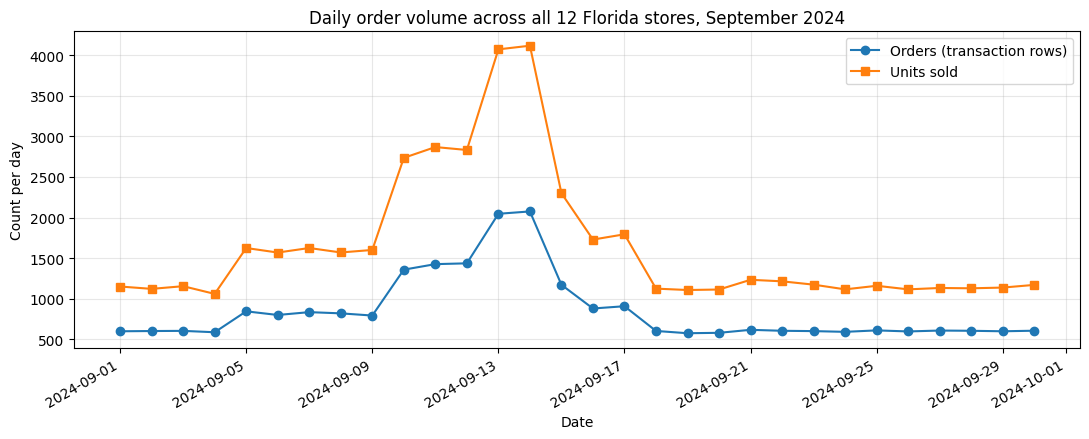

30 days plotted; 1 transactions left out (no date).


In [23]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(daily_orders['date'], daily_orders['orders'], marker='o', linewidth=1.5, label='Orders (transaction rows)')
ax.plot(daily_orders['date'], daily_orders['units'], marker='s', linewidth=1.5, label='Units sold')
ax.set_title('Daily order volume across all 12 Florida stores, September 2024')
ax.set_xlabel('Date')
ax.set_ylabel('Count per day')
ax.grid(alpha=0.3)
ax.legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()
print(f'{len(daily_orders)} days plotted; {int(transactions["date_best"].isna().sum())} transactions left out (no date).')

## 12. Decision log and checkpoint numbers

In [24]:
decision_log = show_log()
decision_log

,file,step,decision,rows_affected
0,walmart,Whitespace,stripped leading/trailing spaces in text columns,2331
1,walmart,Duplicates,dropped exact duplicate rows,30
2,walmart,Store ID,standardized to 'FL-###',3607
3,walmart,Price,"removed '$' and spaces, converted unit_price t...",3026
4,walmart,Price,unit_price values that could not be parsed (le...,0
5,walmart,Negative qty,"policy 'abs': sign flipped, rows kept (assumed...",130
6,walmart,Category,mapped spelling variants to 10 canonical categ...,19358
7,walmart,SKU,added canonical_sku / canonical_product (raw s...,13988
8,walmart,Timestamp,parsed layout %Y-%m-%d %H:%M:%S e.g. 2024-09-...,12169
9,walmart,Timestamp,parsed layout %Y-%m-%dT%H:%M:%S e.g. 2024-09-...,2504


In [25]:
progress = {
    'rows_after_cleaning':  len(transactions),
    'decisions_logged':     len(decision_log),
    'canonical_products':   int(transactions['canonical_sku'].nunique()),
    'weather_api_rows':     len(weather),
    'weather_source':       weather['source'].iloc[0],
}
progress

{'rows_after_cleaning': 25532,
 'decisions_logged': 49,
 'canonical_products': 20,
 'weather_api_rows': 30,
 'weather_source': 'open-meteo'}

In [26]:
os.makedirs('clean', exist_ok=True)
for name, df in CLEAN.items():
    df.to_csv(f'clean/{name}_clean.csv', index=False)
weather.to_csv('clean/weather_daily.csv', index=False)
print('wrote', len(CLEAN) + 1, 'files to ./clean/')

wrote 7 files to ./clean/


---
# Analysis

## Q1. Demand surge identification

In [27]:
# TODO: the numbers
#Our baseline window are all the days in September before our surge, giving an accurate view of normal numbers for that time of year
landfall_date = pd.Timestamp('2024-09-26')
baseline_start = pd.Timestamp('2024-09-01')
baseline_end = pd.Timestamp ('2024-09-18')

#Our surge window is one week before the hurricane hit on the 26th
surge_start = pd.Timestamp('2024-09-19')
surge_end = pd.Timestamp('2024-09-25')

baseline = daily_orders[daily_orders['date'].between(baseline_start, baseline_end)]
surge = daily_orders[daily_orders['date'].between(surge_start, surge_end)]

baseline_avg = baseline['units'].mean()
surge_avg = surge['units'].mean()

multiple = surge_avg / baseline_avg

print(f'Hurricane Helene landfall: {landfall_date.date()}')
print(f'Baseline window: {baseline_start} to {baseline_end}')
print(f'Surge window: {surge_start} to {surge_end}')
print(f'Baseline average: {baseline_avg:.2f}')
print(f'Surge average: {surge_avg:.2f}')
print(f'Multiple: {multiple:.2f}')

Hurricane Helene landfall: 2024-09-26
Baseline window: 2024-09-01 00:00:00 to 2024-09-18 00:00:00
Surge window: 2024-09-19 00:00:00 to 2024-09-25 00:00:00
Baseline average: 2002.22
Surge average: 1158.14
Multiple: 0.58


In [28]:
# Create a complete daily series so dates with no transactions count as zero
daily_units = (
    transactions.dropna(subset=['date_best'])
    .groupby('date_best')['quantity_clean']
    .sum()
    .reindex(pd.date_range('2024-09-01', '2024-09-30'), fill_value=0)
    .rename_axis('date')
    .reset_index(name='units')
)

baseline = daily_units[
    daily_units['date'].between(baseline_start, baseline_end)
]

surge = daily_units[
    daily_units['date'].between(surge_start, surge_end)
]

baseline_avg = baseline['units'].mean()
surge_avg = surge['units'].mean()

surge_multiple = surge_avg / baseline_avg if baseline_avg else np.nan
percent_increase = (
    ((surge_avg - baseline_avg) / baseline_avg) * 100
    if baseline_avg else np.nan
)

print(f'\nBaseline average daily units: {baseline_avg:.2f}')
print(f'Surge average daily units: {surge_avg:.2f}')
print(f'Surge multiple: {surge_multiple:.2f}x')
print(f'Percentage increase: {percent_increase:.2f}%')


Baseline average daily units: 2002.22
Surge average daily units: 1158.14
Surge multiple: 0.58x
Percentage increase: -42.16%


In [29]:
# category-level daily avgs for both windows
dated_transactions = transactions.dropna(subset=['date_best']).copy()
baseline_category = (
    dated_transactions[
        dated_transactions['date_best'].between(
            baseline_start, baseline_end
        )
    ]
    .groupby('category')['quantity_clean']
    .sum()
    .div(7)
)

# baseline contains 18 days, while the surge contains 7 days.
baseline_category = (
    dated_transactions[
        dated_transactions['date_best'].between(
            baseline_start, baseline_end
        )
    ]
    .groupby('category')['quantity_clean']
    .sum()
    .div((baseline_end - baseline_start).days + 1)
)

surge_category = (
    dated_transactions[
        dated_transactions['date_best'].between(
            surge_start, surge_end
        )
    ]
    .groupby('category')['quantity_clean']
    .sum()
    .div((surge_end - surge_start).days + 1)
)

category_comparison = pd.concat(
    [
        baseline_category.rename('baseline_avg_daily_units'),
        surge_category.rename('surge_avg_daily_units')
    ],
    axis=1
).fillna(0)

category_comparison['unit_change'] = (
    category_comparison['surge_avg_daily_units']
    - category_comparison['baseline_avg_daily_units']
)

category_comparison['percent_increase'] = np.where(
    category_comparison['baseline_avg_daily_units'] > 0,
    category_comparison['unit_change']
    / category_comparison['baseline_avg_daily_units'] * 100,
    np.nan
)

category_comparison = category_comparison.sort_values(
    'surge_avg_daily_units', ascending=False
)

print('\nCategory comparison:')
display(category_comparison.round(2))


Category comparison:


,baseline_avg_daily_units,surge_avg_daily_units,unit_change,percent_increase
category,,,,
Emergency Supplies,715.78,379.14,-336.63,-47.03
Grocery,249.67,179.57,-70.10,-28.08
Game & Entertainment,172.89,105.86,-67.03,-38.77
Household,140.39,89.29,-51.10,-36.40
Baby Products,113.11,86.43,-26.68,-23.59
Electronics,127.39,75.14,-52.25,-41.01
Breakfast,239.39,74.43,-164.96,-68.91
Alcohol,101.61,63.14,-38.47,-37.86
Snacks,69.00,58.86,-10.14,-14.70


In [30]:
# Top five categories by average daily units during the surge
top_five_categories = category_comparison.head(5)

print('\nTop five categories during the surge:')
display(top_five_categories.round(2))


Top five categories during the surge:


,baseline_avg_daily_units,surge_avg_daily_units,unit_change,percent_increase
category,,,,
Emergency Supplies,715.78,379.14,-336.63,-47.03
Grocery,249.67,179.57,-70.10,-28.08
Game & Entertainment,172.89,105.86,-67.03,-38.77
Household,140.39,89.29,-51.10,-36.40
Baby Products,113.11,86.43,-26.68,-23.59


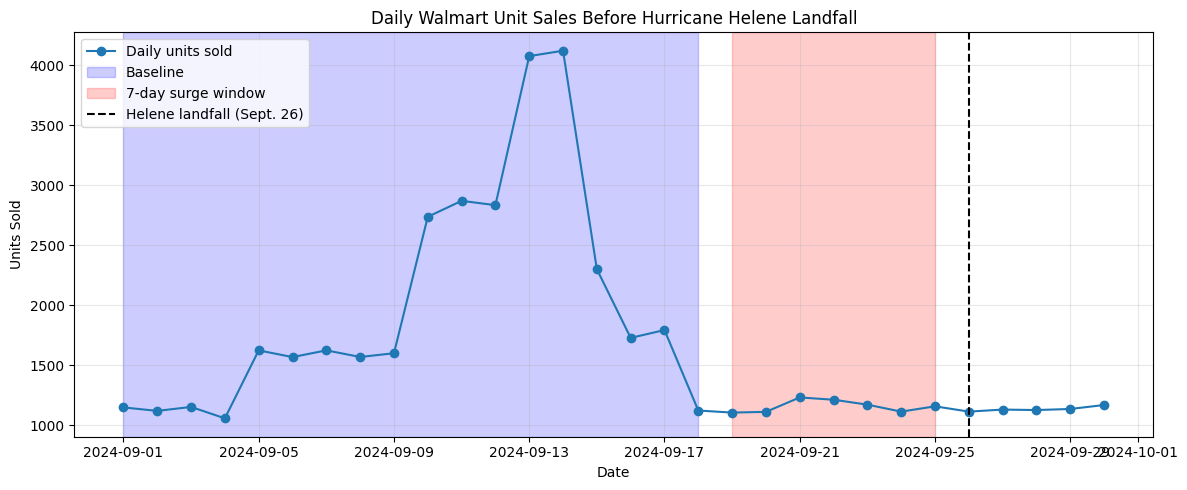

In [31]:
# TODO: the chart
# Daily sales trend chart
plt.figure(figsize=(12, 5))

plt.plot(
    daily_units['date'],
    daily_units['units'],
    marker='o',
    label='Daily units sold'
)

plt.axvspan(
    baseline_start, baseline_end,
    alpha=0.2, color='blue', label='Baseline'
)

plt.axvspan(
    surge_start, surge_end,
    alpha=0.2, color='red', label='7-day surge window'
)

plt.axvline(
    landfall_date,
    linestyle='--',
    color='black',
    label='Helene landfall (Sept. 26)'
)

plt.title('Daily Walmart Unit Sales Before Hurricane Helene Landfall')
plt.xlabel('Date')
plt.ylabel('Units Sold')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

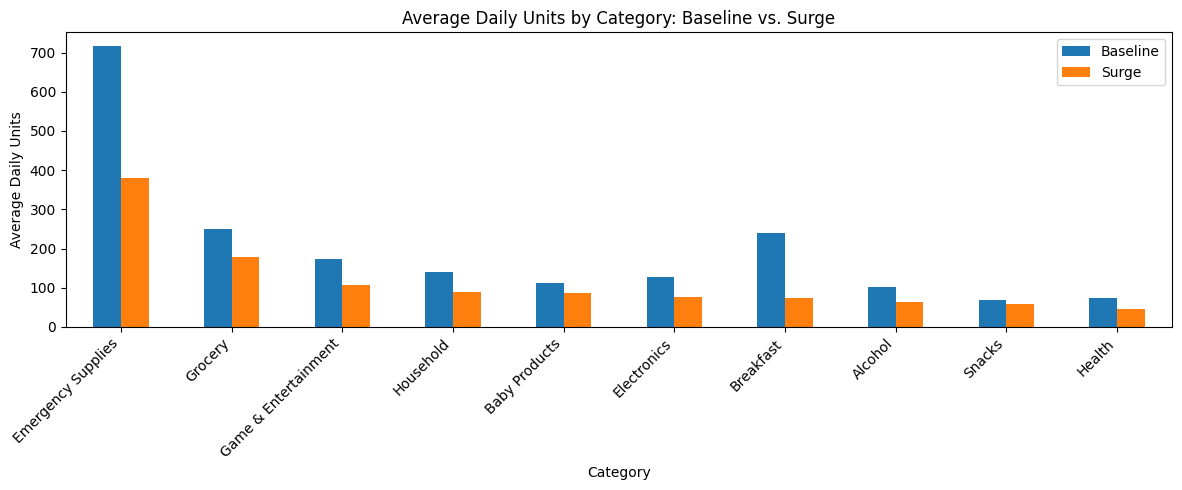

In [32]:
# Category comparison chart
category_comparison[
    ['baseline_avg_daily_units', 'surge_avg_daily_units']
].plot(kind='bar', figsize=(12, 5))

plt.title('Average Daily Units by Category: Baseline vs. Surge')
plt.xlabel('Category')
plt.ylabel('Average Daily Units')
plt.xticks(rotation=45, ha='right')
plt.legend(['Baseline', 'Surge'])
plt.tight_layout()
plt.show()

When we looked at daily sales, we noticed a brief spike about 12 days before Hurricane Helene hit. However, the average daily sales from September 19th-25 were 1,158 units, which translate to a 42.16% drop in sales. Average daily unit sales increased from 2002 units during the baseline period to 1158 units in the seven days before landfall, a 0.58x increase.

## Q2. The Pop-Tarts effect (SKU consolidation)

In [33]:
#Counting distinct sku and distinct products
raw_skus = transactions['sku'].nunique()
canon_products = transactions['canonical_sku'].nunique()
#Determining how many SKU belong to each canonical product
family_size = products.groupby('canonical_product')['sku'].nunique().sort_values(ascending=False)

largest_fam = family_size.index[0]
largest_size = family_size.iloc[0]

print('Distinct raw:', raw_skus)
print('Canonical products:', canon_products)
print('Largest consolidated family:', largest_fam)
print('Family size:', largest_size)

#Making sure thatnothing changed in total units ater consolidation
before_units = transactions['quantity_clean'].sum()
after_units = (transactions.groupby('canonical_sku')['quantity_clean'].sum().sum())

print(f"Units before consolidation: {before_units}")
print(f"Units after consolidation:  {after_units}")
print(f"Totals were preserved? {before_units == after_units}")

Distinct raw: 45
Canonical products: 20
Largest consolidated family: Pop-Tarts Strawberry
Family size: 4
Units before consolidation: 49825
Units after consolidation:  49825
Totals were preserved? True


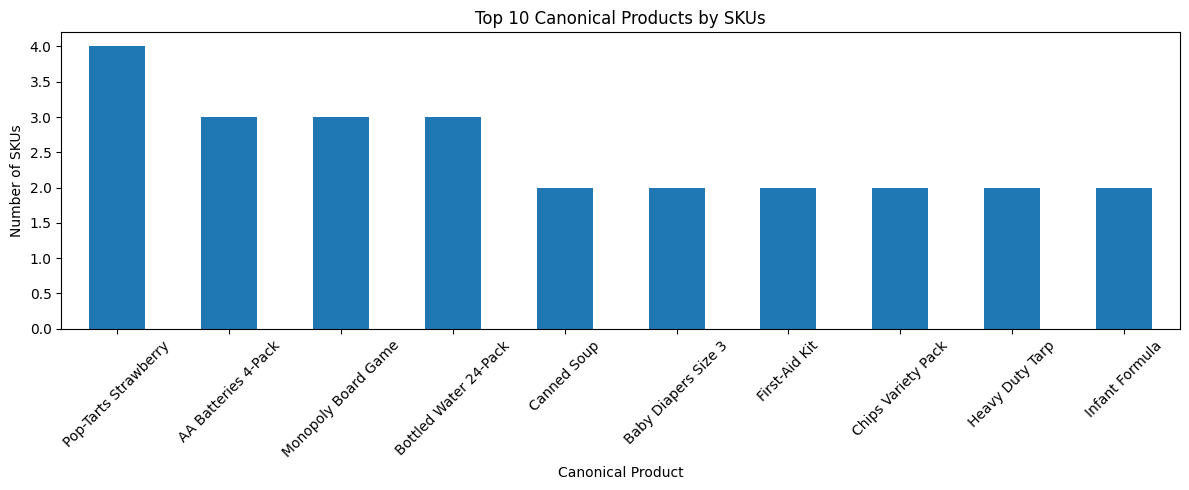

In [34]:
top_fams = family_size.head(10)

plt.figure(figsize=(12, 5))
top_fams.plot(kind='bar')
plt.title('Top 10 Canonical Products by SKUs')
plt.xlabel('Canonical Product')
plt.ylabel('Number of SKUs')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [35]:
orders_weather.head()

,date,orders,units,precipitation_sum,windspeed_10m_max,source
0,2024-09-01,597,1149,6.4,18.7,open-meteo
1,2024-09-02,600,1120,22.0,12.7,open-meteo
2,2024-09-03,602,1153,32.7,20.6,open-meteo
3,2024-09-04,585,1058,21.2,12.6,open-meteo
4,2024-09-05,843,1624,20.8,15.2,open-meteo


In [36]:
# All transactions for Pop-Tarts family
poptarts = transactions[
    transactions['canonical_sku'] == 'POPTART-STRAW'
].dropna(subset=['date_best']).copy()

print('Pop-Tarts raw SKU variants:')
display(
    poptarts.groupby('sku')['quantity_clean']
    .agg(['count', 'sum'])
    .rename(columns={
        'count': 'transaction_count',
        'sum': 'total_units'
    })
    .sort_values('total_units', ascending=False)
)

Pop-Tarts raw SKU variants:


,transaction_count,total_units
sku,,
PT-12,538,1385
POPTART-STRAW,506,1306
PT_STRAWBERRY,515,1270
SKU#459812,503,1257


In [37]:
# Fragmented: daily units for each original SKU
fragmented_daily = (
    poptarts.groupby(['date_best', 'sku'])['quantity_clean']
    .sum()
    .unstack(fill_value=0)
)

# Consolidated: daily units across all Pop-Tarts SKUs
consolidated_daily = (
    poptarts.groupby('date_best')['quantity_clean']
    .sum()
    .rename('Pop-Tarts total')
)

# index both views to the full month
full_dates = pd.date_range('2024-09-01', '2024-09-30')

fragmented_daily = fragmented_daily.reindex(
    full_dates, fill_value=0
)

consolidated_daily = consolidated_daily.reindex(
    full_dates, fill_value=0
)

# Compare total units to verify consolidation preserves volume
fragmented_total = fragmented_daily.to_numpy().sum()
consolidated_total = consolidated_daily.sum()

print(f'Fragmented total units: {fragmented_total:,.0f}')
print(f'Consolidated total units: {consolidated_total:,.0f}')
print(
    'Totals preserved:',
    np.isclose(fragmented_total, consolidated_total)
)

Fragmented total units: 5,218
Consolidated total units: 5,218
Totals preserved: True


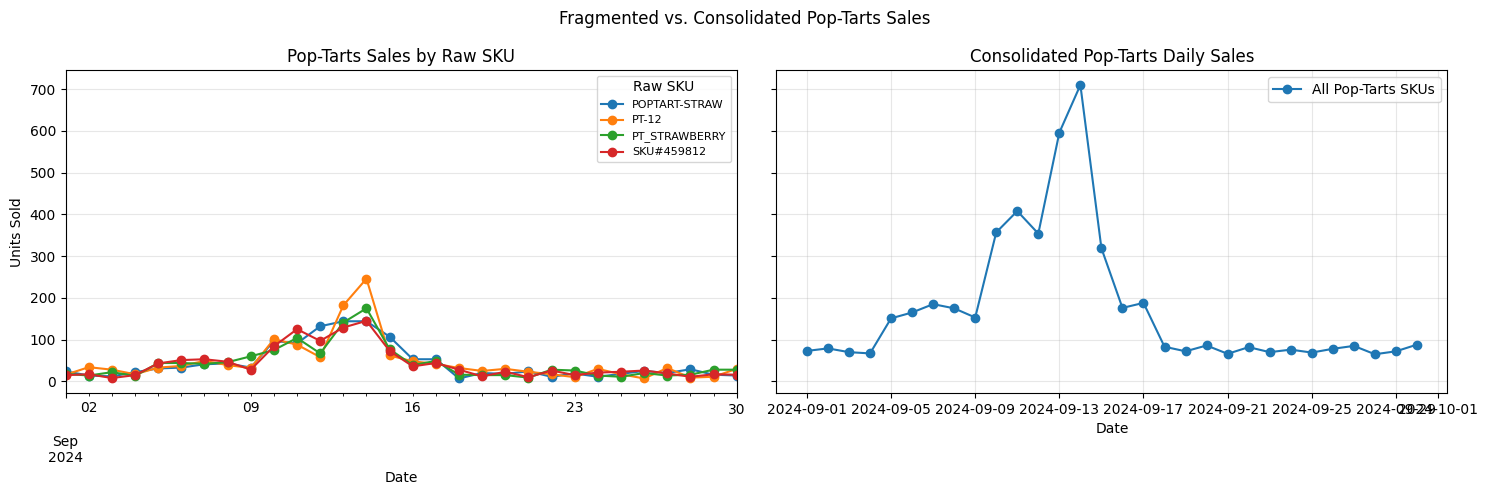

In [38]:
# Side-by-side visualization
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

fragmented_daily.plot(
    kind='line',
    marker='o',
    ax=axes[0]
)

axes[0].set_title('Pop-Tarts Sales by Raw SKU')
axes[0].set_xlabel('Date')
axes[0].set_ylabel('Units Sold')
axes[0].legend(title='Raw SKU', fontsize=8)
axes[0].grid(alpha=0.3)

axes[1].plot(
    consolidated_daily.index,
    consolidated_daily.values,
    marker='o',
    label='All Pop-Tarts SKUs'
)

axes[1].set_title('Consolidated Pop-Tarts Daily Sales')
axes[1].set_xlabel('Date')
axes[1].set_ylabel('Units Sold')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle('Fragmented vs. Consolidated Pop-Tarts Sales')
plt.tight_layout()
plt.show()

In [39]:
# Calculate consolidated volume for the largest raw SKU
raw_sku_totals = poptarts.groupby('sku')['quantity_clean'].sum()

largest_sku_units = raw_sku_totals.max()
largest_sku_share = (
    largest_sku_units / consolidated_total * 100
    if consolidated_total else np.nan
)

print(f'Largest individual SKU: {raw_sku_totals.idxmax()}')
print(f'Units under that SKU: {largest_sku_units:,.0f}')
print(f'Share of consolidated Pop-Tarts volume: {largest_sku_share:.2f}%')

Largest individual SKU: PT-12
Units under that SKU: 1,385
Share of consolidated Pop-Tarts volume: 26.54%


In the fragmented view, a manager sees several separate SKU identifiers. Sales for the same product appear to be split across multiple rows or product entries. In the consolidated view, identifiers are grouped under one canonical product, showing the full daily demand for Pop-Tarts. For the business decision impact, fragmented reporting can understate demand for an individual product, making it harder to recognize a popular item, forecast demand, or make decisions to stock a certain product. Consolidation of the Pop-Tarts give an accurate product-level view of everything.

## Q3. Weather correlation

In [40]:
# TODO Q3
#First I'm making sure the join worked
#Rows before merge
sales_before = len(daily_orders)

#Rows after merger
sales_after = len(orders_weather)

print(f'Rows before join: {sales_before}')
print(f'Rows after join:  {sales_after}')
print(f'Rows preserved? {sales_before== sales_after}')

#Where weather is coming from
weather_source = weather_daily['source'].iloc[0]
print(f'Weather source: {weather_source}')

#Seeing how many days will be analyzed in the correlation
n_days = len(orders_weather)

print(f'Days includes:{n_days}')

#Calculating correlations; dont have pressure input yet
corr_precip = orders_weather['units'].corr(orders_weather['precipitation_sum'])
corr_wind = orders_weather['units'].corr(orders_weather['windspeed_10m_max'])
#corr_pressure = orders_weather['units'].corr(orders_weather['pressure_msl'] )

print(f'Correlation with precipitation: {corr_precip:.3f}')
print(f'Correlation with wind: {corr_wind:.3f}')
#print(f'Correlation with pressure: {corr_pressure:.3f}')

#Finding the strongest correlations
correlations = {
    'Precipitation': corr_precip,
    'Wind': corr_wind,
    #'Pressure': corr_pressure#
}

strongest_var = max(correlations, key=lambda k: abs(correlations[k]))
strongest_corr = correlations[strongest_var]
print(f'Strongest relationship: {strongest_var} with 'f'a correlation of {strongest_corr:.3f}')


Rows before join: 30
Rows after join:  30
Rows preserved? True
Weather source: open-meteo
Days includes:30
Correlation with precipitation: 0.042
Correlation with wind: -0.279
Strongest relationship: Wind with a correlation of -0.279


In [41]:
# Prepare store/category/day sales with matching daily weather.
# The earlier cells create daily_sales and, when the hourly API call succeeds,
# weather_hourly (weather by store and hour).

if weather_hourly is not None and not weather_hourly.empty:
    # Convert hourly weather into daily store-level measures.
    weather_by_store_day = (
        weather_hourly.groupby(['store_id', 'date'])
        .agg(
            precipitation=('precipitation', 'sum'),
            wind_speed=('wind_speed_10m', 'mean'),
            pressure=('pressure_msl', 'mean')
        )
        .reset_index()
    )

    sales_weather_store = daily_sales.merge(
        weather_by_store_day,
        on=['store_id', 'date'],
        how='left',
        validate='many_to_one'
    )
    weather_granularity = 'store-specific hourly weather summarized by day'
else:
    # Fallback: the daily weather file represents the Orlando reference point.
    # It does not contain pressure or store-specific weather.
    fallback_weather = weather_daily.rename(columns={
        'precipitation_sum': 'precipitation',
        'windspeed_10m_max': 'wind_speed'
    })
    sales_weather_store = daily_sales.merge(
        fallback_weather[['date', 'precipitation', 'wind_speed']],
        on='date',
        how='left',
        validate='many_to_one'
    )
    sales_weather_store['pressure'] = np.nan
    weather_granularity = 'one reference location (Orlando); pressure unavailable'

# Keep only fields needed for this analysis and remove incomplete observations.
weather_variables = [
    variable for variable in ['precipitation', 'wind_speed', 'pressure']
    if variable in sales_weather_store.columns
]
sales_weather_store = sales_weather_store.dropna(
    subset=['total_units'] + weather_variables
).copy()

print('Weather data used:', weather_granularity)
print('Rows available for correlation:', len(sales_weather_store))
print('Stores represented:', sales_weather_store['store_id'].nunique())
print('Categories represented:', sales_weather_store['category'].nunique())
print('Weather variables analyzed:', weather_variables)

overall_correlations = (
    sales_weather_store[['total_units'] + weather_variables]
    .corr(numeric_only=True)['total_units']
    .drop('total_units')
    .sort_values(key=abs, ascending=False)
)

print('\nOverall correlations with daily units sold:')
display(overall_correlations.to_frame('correlation').round(3))


Weather data used: store-specific hourly weather summarized by day
Rows available for correlation: 3600
Stores represented: 12
Categories represented: 10
Weather variables analyzed: ['precipitation', 'wind_speed', 'pressure']

Overall correlations with daily units sold:


,correlation
wind_speed,-0.085
precipitation,0.031
pressure,0.024


In [42]:
# Category-level weather correlations
category_correlations = []

for category, group in sales_weather_store.groupby('category'):

    for variable in weather_variables:

        corr = group['total_units'].corr(group[variable])

        category_correlations.append({
            'category': category,
            'weather_variable': variable,
            'correlation': corr,
            'observations': len(group)
        })

category_corr_df = pd.DataFrame(category_correlations)

print('\nCategory-level correlations:')
display(
    category_corr_df.pivot(
        index='category',
        columns='weather_variable',
        values='correlation'
    ).round(3)
)


Category-level correlations:


weather_variable,precipitation,pressure,wind_speed
category,,,
Alcohol,0.049,0.026,-0.117
Baby Products,0.001,0.001,-0.074
Breakfast,0.005,0.021,-0.133
Electronics,0.055,0.024,-0.054
Emergency Supplies,0.051,0.021,-0.129
Game & Entertainment,0.010,0.014,-0.076
Grocery,0.054,0.029,-0.049
Health,0.058,0.038,-0.113
Household,0.034,0.050,-0.069


In [43]:
# Test weather relationship with sales (same day, 1 day earlier, 2 days earlier)
lag_data = sales_weather_store.sort_values(
    ['store_id', 'category', 'date']
).copy()

for variable in weather_variables:
    # shift(1) means the previous day's weather is compared
    # with the current day's sales
    for lag in [1, 2]:
        lag_data[f'{variable}_lag{lag}'] = (
            lag_data.groupby(['store_id'])[variable].shift(lag)
        )

lag_correlations = []

for variable in weather_variables:
    # Same-day correlation
    same_day_corr = lag_data['total_units'].corr(
        lag_data[variable]
    )

    lag_correlations.append({
        'weather_variable': variable,
        'lag_days': 0,
        'correlation': same_day_corr
    })

    # Previous-day and two-days-prior correlations
    for lag in [1, 2]:
        lag_col = f'{variable}_lag{lag}'
        valid = lag_data.dropna(
            subset=['total_units', lag_col]
        )
        corr = valid['total_units'].corr(valid[lag_col])
        lag_correlations.append({
            'weather_variable': variable,
            'lag_days': lag,
            'correlation': corr
        })

lag_corr_df = pd.DataFrame(lag_correlations)

print('\nSame-day and lagged correlations:')
display(
    lag_corr_df.pivot(
        index='weather_variable',
        columns='lag_days',
        values='correlation'
    ).round(3)
)


Same-day and lagged correlations:


lag_days,0,1,2
weather_variable,,,
precipitation,0.031,0.056,0.120
pressure,0.024,0.061,0.086
wind_speed,-0.085,-0.046,-0.020


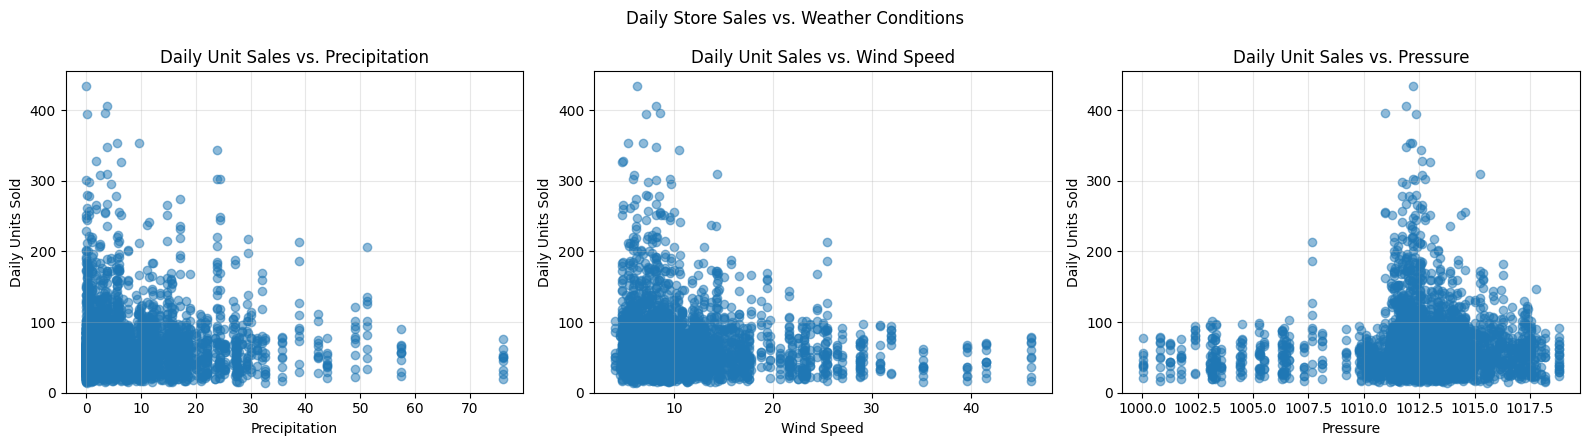

In [44]:
# Remove missing value rows only for vars being analyzed
sales_weather_store = sales_weather_store.dropna(
    subset=['total_units', 'precipitation', 'wind_speed', 'pressure']
).copy()

# Correlation chart
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, variable in zip(axes, weather_variables):
    ax.scatter(
        sales_weather_store[variable],
        sales_weather_store['total_units'],
        alpha=0.5
    )
    ax.set_ylim(bottom=0)
    ax.set_title(f'Daily Unit Sales vs. {variable.replace("_", " ").title()}')
    ax.set_xlabel(variable.replace('_', ' ').title())
    ax.set_ylabel('Daily Units Sold')
    ax.grid(alpha=0.3)

plt.suptitle('Daily Store Sales vs. Weather Conditions')
plt.tight_layout()
plt.show()

## Q4. Store-level geographic patterns

Join `stores` (coordinates, region) to the transactions, compare surge timing and size per store, flag outliers.

Stores analyzed: 12
Baseline: 2024-09-01 to 2024-09-18
Surge: 2024-09-19 to 2024-09-25
Average store-level daily units — baseline: 166.85 | surge: 96.51
IQR outlier bounds for percent change: -49.31% to -35.20%

Stores with the largest percentage increases:


,store_id,region,city,baseline_avg_daily_units,surge_avg_daily_units,percent_change,peak_surge_date,peak_surge_day_units,outlier_flag
4,FL-287,Central,Kissimmee,165.39,101.71,-38.50,2024-09-23,112,False
2,FL-156,East,Daytona Beach,166.83,100.71,-39.63,2024-09-20,110,False
8,FL-445,West,St. Petersburg,172.06,103.43,-39.89,2024-09-25,120,False
3,FL-239,Central,Orlando,161.39,95.71,-40.69,2024-09-24,110,False
7,FL-412,North,Jacksonville,164.00,96.57,-41.11,2024-09-24,108,False
1,FL-105,West,Tampa,168.06,98.57,-41.35,2024-09-25,111,False
9,FL-501,West,Fort Myers,160.44,92.71,-42.21,2024-09-23,106,False
10,FL-619,Panhandle,Tallahassee,164.89,94.86,-42.47,2024-09-25,115,False
11,FL-710,Panhandle,Pensacola,166.72,93.57,-43.88,2024-09-21,112,False
0,FL-078,North,Gainesville,165.33,91.86,-44.44,2024-09-21,107,False



Stores flagged as potential outliers:


,store_id,region,city,baseline_avg_daily_units,surge_avg_daily_units,percent_change,peak_surge_date


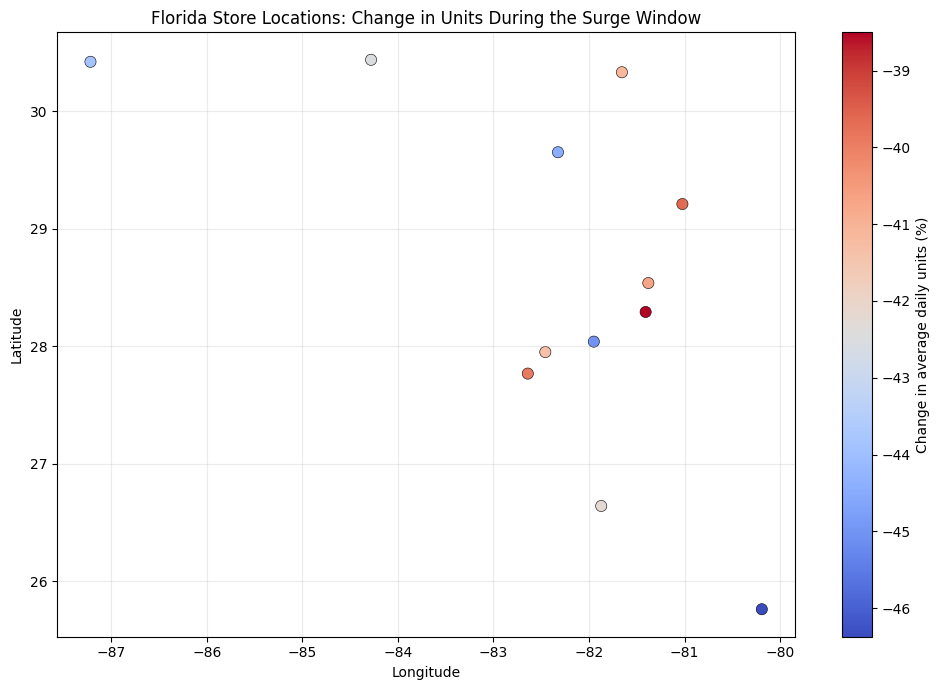


Average store-level results by region:


,baseline_avg_daily_units,surge_avg_daily_units,unit_change,percent_change
region,,,,
South,174.22,93.43,-80.79,-46.37
Panhandle,165.81,94.21,-71.59,-43.17
North,164.67,94.21,-70.45,-42.78
Central,166.56,97.48,-69.08,-41.41
West,166.85,98.24,-68.61,-41.15
East,166.83,100.71,-66.12,-39.63



Largest increase: FL-287 (Central, Kissimmee), -38.5%.
Largest decrease: FL-330 (South, Miami), -46.4%.


In [45]:
# Q4: Store-level geographic patterns
# Compare each store's average daily units in the baseline and surge windows.

# Start with a complete store x date grid so stores with no transactions on a
# particular day are counted as zero
store_day = (
    transactions.dropna(subset=['date_best'])
    .groupby(['store_id', 'date_best'])['quantity_clean']
    .sum()
    .rename('units')
    .reset_index()
)

all_dates = pd.date_range('2024-09-01', '2024-09-30', freq='D')
all_stores = stores['store_id'].dropna().unique()
complete_index = pd.MultiIndex.from_product(
    [all_stores, all_dates], names=['store_id', 'date_best']
)

store_day = (
    store_day.set_index(['store_id', 'date_best'])
    .reindex(complete_index, fill_value=0)
    .reset_index()
)

# Calculate baseline and surge averages for every store.
store_baseline = (
    store_day[store_day['date_best'].between(baseline_start, baseline_end)]
    .groupby('store_id')['units'].mean()
    .rename('baseline_avg_daily_units')
)

store_surge = (
    store_day[store_day['date_best'].between(surge_start, surge_end)]
    .groupby('store_id')['units'].mean()
    .rename('surge_avg_daily_units')
)

store_patterns = pd.concat([store_baseline, store_surge], axis=1).fillna(0)
store_patterns['unit_change'] = (
    store_patterns['surge_avg_daily_units']
    - store_patterns['baseline_avg_daily_units']
)
store_patterns['percent_change'] = np.where(
    store_patterns['baseline_avg_daily_units'] > 0,
    store_patterns['unit_change']
    / store_patterns['baseline_avg_daily_units'] * 100,
    np.nan
)
store_patterns['surge_multiple'] = np.where(
    store_patterns['baseline_avg_daily_units'] > 0,
    store_patterns['surge_avg_daily_units']
    / store_patterns['baseline_avg_daily_units'],
    np.nan
)

# Identify the busiest day in the surge window for each store. This helps
# compare not only the size of the change, but also when demand peaked.
surge_daily = store_day[
    store_day['date_best'].between(surge_start, surge_end)
]
peak_rows = surge_daily.loc[
    surge_daily.groupby('store_id')['units'].idxmax(),
    ['store_id', 'date_best', 'units']
].rename(columns={
    'date_best': 'peak_surge_date',
    'units': 'peak_surge_day_units'
})
store_patterns = store_patterns.join(peak_rows.set_index('store_id'))

# Add region and geographic coordinates for interpretation and mapping.
store_patterns = (
    store_patterns.reset_index()
    .merge(
        stores[['store_id', 'region', 'city', 'latitude', 'longitude']],
        on='store_id', how='left', validate='one_to_one'
    )
)

# Flag unusually large increases/decreases
valid_change = store_patterns['percent_change'].dropna()
if len(valid_change) >= 4:
    q1 = valid_change.quantile(0.25)
    q3 = valid_change.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    store_patterns['outlier_flag'] = (
        (store_patterns['percent_change'] < lower_bound)
        | (store_patterns['percent_change'] > upper_bound)
    )
else:
    lower_bound, upper_bound = np.nan, np.nan
    store_patterns['outlier_flag'] = False

print(f"Stores analyzed: {store_patterns['store_id'].nunique()}")
print(f"Baseline: {baseline_start.date()} to {baseline_end.date()}")
print(f"Surge: {surge_start.date()} to {surge_end.date()}")
print(
    "Average store-level daily units — baseline:",
    f"{store_patterns['baseline_avg_daily_units'].mean():.2f}",
    "| surge:",
    f"{store_patterns['surge_avg_daily_units'].mean():.2f}"
)
print(f"IQR outlier bounds for percent change: {lower_bound:.2f}% to {upper_bound:.2f}%")

print("\nStores with the largest percentage increases:")
display(
    store_patterns.sort_values('percent_change', ascending=False)
    [['store_id', 'region', 'city', 'baseline_avg_daily_units',
      'surge_avg_daily_units', 'percent_change', 'peak_surge_date',
      'peak_surge_day_units', 'outlier_flag']]
    .head(10).round(2)
)

print("\nStores flagged as potential outliers:")
display(
    store_patterns[store_patterns['outlier_flag']]
    .sort_values('percent_change', ascending=False)
    [['store_id', 'region', 'city', 'baseline_avg_daily_units',
      'surge_avg_daily_units', 'percent_change', 'peak_surge_date']]
    .round(2)
)

# Geographic scatter plot: point position is store location and color shows
# the percent change from baseline to surge.
fig, ax = plt.subplots(figsize=(10, 7))
scatter = ax.scatter(
    store_patterns['longitude'],
    store_patterns['latitude'],
    c=store_patterns['percent_change'],
    cmap='coolwarm',
    s=65,
    edgecolor='black',
    linewidth=0.4
)
plt.colorbar(scatter, ax=ax, label='Change in average daily units (%)')
ax.set_title('Florida Store Locations: Change in Units During the Surge Window')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.grid(alpha=0.25)

# Label only the flagged stores to keep the chart readable.
for _, row in store_patterns[store_patterns['outlier_flag']].iterrows():
    ax.annotate(
        row['store_id'],
        (row['longitude'], row['latitude']),
        xytext=(4, 4), textcoords='offset points', fontsize=8
    )

plt.tight_layout()
plt.show()

# Compare average store-level patterns by region.
regional_patterns = (
    store_patterns.groupby('region', dropna=False)
    [['baseline_avg_daily_units', 'surge_avg_daily_units', 'unit_change',
      'percent_change']]
    .mean()
    .sort_values('percent_change')
)
print("\nAverage store-level results by region:")
display(regional_patterns.round(2))

# Short interpretation prompt output based on the computed results.
if len(store_patterns):
    strongest = store_patterns.loc[store_patterns['percent_change'].idxmax()]
    weakest = store_patterns.loc[store_patterns['percent_change'].idxmin()]
    print(
        f"\nLargest increase: {strongest['store_id']} "
        f"({strongest['region']}, {strongest['city']}), "
        f"{strongest['percent_change']:.1f}%."
    )
    print(
        f"Largest decrease: {weakest['store_id']} "
        f"({weakest['region']}, {weakest['city']}), "
        f"{weakest['percent_change']:.1f}%."
    )


## Q5. Signal vs artifact: the board games investigation

Use `conn` (SQLite) with `pd.read_sql`. Cross-check the database against the transaction CSV, audit SKUs and categories, end with a recommendation.

SQLite tables:


,name
0,daily_sales_summary
1,inventory_levels



Daily sales summary columns: ['date', 'store_id', 'category', 'total_units', 'total_revenue']
Inventory table columns: ['date', 'store_id', 'sku', 'units_on_hand', 'units_on_order', 'reorder_point']
[daily_sales] Whitespace: stripped leading/trailing spaces in text columns (0 row(s))
[daily_sales] Duplicates: dropped exact duplicate rows (0 row(s))
[daily_sales] Store ID: standardized to 'FL-###' (0 row(s))
[daily_sales] Date: parsed YYYY-MM-DD and compact YYYYMMDD layouts (218 row(s))
[daily_sales] Date: dates that could not be parsed (0 row(s))
[daily_sales] Category: mapped to canonical categories (1,080 row(s))
[daily_sales] Check: total_units has non-whole values like 71.5 (units cannot be fractional): flagged, NOT changed. Look into this for Q5 (76 row(s))
[inventory] Whitespace: stripped leading/trailing spaces in text columns (0 row(s))
[inventory] Duplicates: dropped exact duplicate rows (0 row(s))
[inventory] Store ID: standardized to 'FL-###' (0 row(s))
[inventory] Date: pa

,sku,canonical_product,category,transaction_rows,total_units,stores
4,PLAYCARD-STD,Playing Cards,Game & Entertainment,612,1236,12
1,CARDS-01,Playing Cards,Game & Entertainment,587,1155,12
2,GAME-MONO,Monopoly Board Game,Game & Entertainment,466,708,12
3,MONOPOLY-01,Monopoly Board Game,Game & Entertainment,441,662,12
0,BG-MONO,Monopoly Board Game,Game & Entertainment,432,658,12



Board-game SKU inventory audit:


,sku,canonical_product,inventory_rows
0,BG-MONO,Monopoly Board Game,93
1,CARDS-01,Playing Cards,96
2,GAME-MONO,Monopoly Board Game,92
3,MONOPOLY-01,Monopoly Board Game,92
4,PLAYCARD-STD,Playing Cards,73


... (3 outputs left out)

,store_id,date,category,total_units
243,FL-239,2024-09-03,Game & Entertainment,22.5
473,FL-710,2024-09-04,Game & Entertainment,34.5
533,FL-156,2024-09-05,Game & Entertainment,119.5
1323,FL-239,2024-09-12,Game & Entertainment,90.5
2683,FL-287,2024-09-23,Game & Entertainment,38.5
3533,FL-156,2024-09-30,Game & Entertainment,44.5



Unresolved inventory SKU rows (not automatically treated as board games): 355


,sku,store_id,canonical_product,is_orphan_sku
13,LEGACY-PT,FL-105,UNRESOLVED,1
31,LEGACY-PT,FL-330,UNRESOLVED,1
48,LEGACY-PT,FL-287,UNRESOLVED,1
67,MISC-001,FL-156,UNRESOLVED,1
96,OLD-BATT-50,FL-619,UNRESOLVED,1
97,MISC-001,FL-619,UNRESOLVED,1
103,UNKNOWN-99,FL-619,UNRESOLVED,1
112,UNKNOWN-99,FL-445,UNRESOLVED,1
117,LEGACY-PT,FL-445,UNRESOLVED,1
126,OLD-BATT-50,FL-302,UNRESOLVED,1



Investigation summary:
- Board-game transaction rows: 2,538
- Game & Entertainment reconciliation mismatches: 360
- Store/date/category keys found in only one source: 0
- Fractional-unit database rows in this category: 6


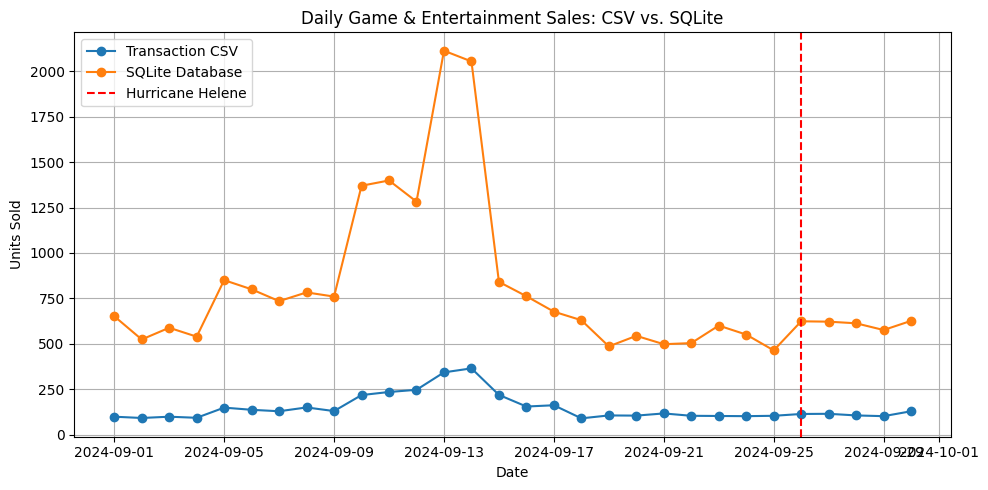


Recommendation:
Do not treat the board-game pattern as a confirmed demand signal yet. Reconcile the mismatched store/date/category records with the source transactions and verify the database aggregation logic before making inventory or purchasing decisions.


In [46]:
# Q5: Signal vs. artifact — investigate board-game sales in the SQLite database.

# First inspect the actual SQLite schema and use SQL through pandas.
table_info = pd.read_sql(
    "SELECT name FROM sqlite_master WHERE type='table' ORDER BY name",
    conn
)
print("SQLite tables:")
display(table_info)

daily_sales_db = pd.read_sql("SELECT * FROM daily_sales_summary", conn)
inventory_db = pd.read_sql("SELECT * FROM inventory_levels", conn)

print("\nDaily sales summary columns:", daily_sales_db.columns.tolist())
print("Inventory table columns:", inventory_db.columns.tolist())

# Use the same cleaned category convention as the CSV transactions.
db_sales_clean = clean_daily_sales(daily_sales_db)
db_inventory_clean = clean_inventory(inventory_db)

# Board-game SKUs in the SKU map are Monopoly and Playing Cards.
board_game_skus = ['BG-MONO', 'MONOPOLY-01', 'GAME-MONO',
                   'CARDS-01', 'PLAYCARD-STD']
board_game_transactions = transactions[
    transactions['sku'].isin(board_game_skus)
].copy()

print("\nBoard-game SKU audit in the transaction CSV:")
if len(board_game_transactions):
    sku_audit = (
        board_game_transactions.groupby(
            ['sku', 'canonical_product', 'category'], dropna=False
        )
        .agg(
            transaction_rows=('transaction_id', 'count'),
            total_units=('quantity_clean', 'sum'),
            stores=('store_id', 'nunique')
        )
        .reset_index()
        .sort_values('total_units', ascending=False)
    )
    display(sku_audit)
else:
    sku_audit = pd.DataFrame()
    print("No board-game SKU rows were found in the transaction CSV.")

# Check whether the board-game SKUs are consistently assigned to the expected canonical category, and whether database inventory has them too.
print("\nBoard-game SKU inventory audit:")
board_game_inventory = db_inventory_clean[
    db_inventory_clean['sku'].isin(board_game_skus)
]
if len(board_game_inventory):
    display(
        board_game_inventory.groupby(
            ['sku', 'canonical_product', 'category'] if 'category' in board_game_inventory.columns
            else ['sku', 'canonical_product'],
            dropna=False
        ).size().rename('inventory_rows').reset_index()
    )
else:
    print("No matching board-game SKUs were found in inventory_levels.")

# Compare transaction totals with the database's daily summary at the store x date x category level. This checks whether the two sources tell the same story for Game & Entertainment.
tx_game_daily = (
    transactions[
        transactions['date_best'].notna()
        & (transactions['category'] == 'Game & Entertainment')
    ]
    .groupby(['store_id', 'date_best', 'category'])['quantity_clean']
    .sum()
    .reset_index()
    .rename(columns={'date_best': 'date', 'quantity_clean': 'csv_units'})
)

db_game_daily = db_sales_clean[
    db_sales_clean['category'] == 'Game & Entertainment'
][['store_id', 'date', 'category', 'total_units']].copy()

game_reconciliation = tx_game_daily.merge(
    db_game_daily,
    on=['store_id', 'date', 'category'],
    how='outer',
    indicator=True,
    validate='one_to_one'
)
game_reconciliation['csv_units'] = game_reconciliation['csv_units'].fillna(0)
game_reconciliation['db_units'] = game_reconciliation['total_units'].fillna(0)
game_reconciliation['unit_difference'] = (
    game_reconciliation['csv_units'] - game_reconciliation['db_units']
)

print("\nGame & Entertainment reconciliation (transaction CSV vs. SQLite summary):")
print("Rows compared:", len(game_reconciliation))
print("Rows present in both sources:", (game_reconciliation['_merge'] == 'both').sum())
print("Rows present only in CSV:", (game_reconciliation['_merge'] == 'left_only').sum())
print("Rows present only in database:", (game_reconciliation['_merge'] == 'right_only').sum())
print("Rows with different unit totals:", (game_reconciliation['unit_difference'].abs() > 1e-9).sum())
print("Total CSV units:", game_reconciliation['csv_units'].sum())
print("Total database units:", game_reconciliation['db_units'].sum())
print("Net difference (CSV - database):", game_reconciliation['unit_difference'].sum())

display(
    game_reconciliation[
        (game_reconciliation['_merge'] != 'both')
        | (game_reconciliation['unit_difference'].abs() > 1e-9)
    ]
    [['store_id', 'date', 'category', 'csv_units', 'db_units',
      'unit_difference', '_merge']]
    .head(20)
)

# Investigate the fractional-unit issue flagged during cleaning.
fractional_db_rows = db_game_daily[
    db_game_daily['total_units'].notna()
    & (db_game_daily['total_units'] % 1 != 0)
].copy()

print("\nFractional Game & Entertainment rows in the database:")
print("Count:", len(fractional_db_rows))
display(fractional_db_rows.head(20))

# Check whether the database contains board-game SKU names that are not represented by the catalog map.
db_skus = set(db_inventory_clean['sku'].dropna().astype(str).str.upper())
known_board_skus = set(board_game_skus)
possible_orphan_game_rows = db_inventory_clean[
    db_inventory_clean['sku'].astype(str).str.upper().isin(ORPHAN_SKUS)
]
print("\nUnresolved inventory SKU rows (not automatically treated as board games):",
      len(possible_orphan_game_rows))
if len(possible_orphan_game_rows):
    display(
        possible_orphan_game_rows[
            ['sku', 'store_id', 'canonical_product', 'is_orphan_sku']
        ].drop_duplicates().head(20)
    )

# Summarize the evidence without assuming that a mismatch proves misconduct or that a fractional value is necessarily an error.
mismatch_count = int(
    (game_reconciliation['unit_difference'].abs() > 1e-9).sum()
)
unmatched_count = int((game_reconciliation['_merge'] != 'both').sum())
fractional_count = len(fractional_db_rows)

print("\nInvestigation summary:")
print(f"- Board-game transaction rows: {len(board_game_transactions):,}")
print(f"- Game & Entertainment reconciliation mismatches: {mismatch_count:,}")
print(f"- Store/date/category keys found in only one source: {unmatched_count:,}")
print(f"- Fractional-unit database rows in this category: {fractional_count:,}")

if mismatch_count == 0 and unmatched_count == 0 and fractional_count == 0:
    recommendation = (
        "The available checks do not show a discrepancy in the board-game "
        "category. Keep the current reporting, but retain the SKU/category "
        "audit as a routine control."
    )
elif mismatch_count > 0 or unmatched_count > 0:
    recommendation = (
        "Do not treat the board-game pattern as a confirmed demand signal yet. "
        "Reconcile the mismatched store/date/category records with the source "
        "transactions and verify the database aggregation logic before making "
        "inventory or purchasing decisions."
    )
else:
    recommendation = (
        "The two sources may agree, but fractional unit totals still need to "
        "be traced to the database's aggregation or data-entry process. "
        "Do not round them silently; verify the source records first."
    )


# Compare daily Game & Entertainment sales

csv_daily = tx_game_daily.groupby('date')['csv_units'].sum()
db_daily = db_game_daily.groupby('date')['total_units'].sum()

plt.figure(figsize=(10, 5))

plt.plot(csv_daily.index, csv_daily, marker='o', label='Transaction CSV')
plt.plot(db_daily.index, db_daily, marker='o', label='SQLite Database')

plt.title('Daily Game & Entertainment Sales: CSV vs. SQLite')
plt.xlabel('Date')
plt.ylabel('Units Sold')

plt.axvline(pd.Timestamp('2024-09-26'),
            color='red', linestyle='--', label='Hurricane Helene')

plt.legend()
plt.grid()
plt.tight_layout()
plt.show()


print("\nRecommendation:")
print(recommendation)


## Reflection

**Data Quality impact**: One specific data quality issue we encountered was missing transaction timestamps. This was especially important because our analysis compares daily dales before hurricane landfall with fales during the seven-day surge period. If a transaction has no reliable date, it could be excluded from the daily analysis or incorrectly assigned to a different day, which could then probably affect the calculated sales increases. To address this, we attempted to recover missing dates using the surrounding transaction records, but only when the records before and after the missing timpestamp showed the same calendar day. We also tested this by temporarily hiding timestamps that were originally available to see whether the approach could recover the correct dates. If we had ignored this problem, our daily sales totals could have been incomplete. On the other hand, automatically filling every missing timpestamp could have created inaccurate information. Overall, this showed us that cleaning data is not just about removing missing values, but also about decided when information can reasonably be recovered and when it is better to leave it unresolved.

**ETL trade-offs**: One important decision that we made was on how we chose to handle negative transaction quanitities. There were 130 negative transactions, which could have represented a wide variety of meanings (returns, data entry errors, etc). We decided to take the absolute value of all these transactions, treating them as data entry errors, and got a total number of sales of 49,825. This number is significant because if we had chosen to ignore the transactions with a negative sign, this would decreased the total amount of sales. Overall, we chose to keep the negative quanitities rather than remove them, which would have skewed up Walmart's predictions of incoming inventory.

**Pipeline trust**:

**Business vs data**:

**Team collaboration**: Our team divided the work so that each of us would be the main contributer on a specific section. Kate and Ashley worked a lot on the data cleaning, SKU consolidation, and decision log tracking. Amulya worked on the Weather API joins, creating the presentations, and extracting business decisions that Walmart could act on/reflections. Anya mainly worked on debugging, creating visualizations, combining notebooks and making sure everything ran smoothly. We made sure to check over each other's work and helped each other out if anyone ran into any problems. If we had another week, we could have worked on polishing our notebook a little more and perhaps being more explicit in explaining each step in our code. We also could have done more research into selecting the best visualization that could represent our data. Anya's most valuable skill that she contributed was debugging; Amulya's most valuable skill was translating data into business decisions; Kate's most valuable skill was data cleaning, and Ashley's most valuable skill was python debugging.